In [2]:
import numpy as np
from scipy.optimize import curve_fit, least_squares
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd
from IPython.display import Latex
import scipy.signal
from scipy.signal import find_peaks

In [1]:
# 'Eyeballed Peaks' Data (average over all 3 trials)

n = np.array([9, 7, 5, 3])

freq = np.array([820.1496667, 638.9353333, 459.2836667, 256.1993333])

freq_error = np.array([2.369858347, 2.69707037, 0.01965536398, 1.363702802])


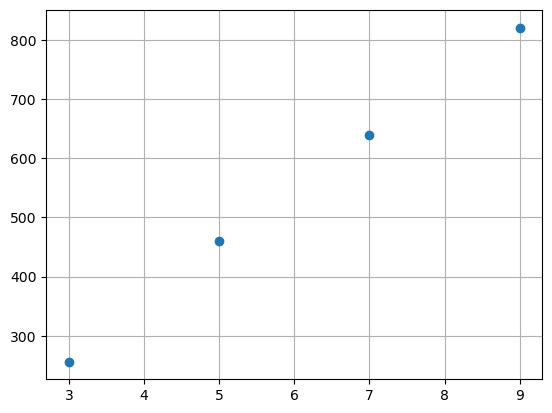

In [17]:
plt.errorbar(n, freq, freq_error, fmt='o')
plt.grid()

m = 93.575133 +- 1.941730
c = -17.808800 +- 12.433136
v_ex = 352.3311132746481 m/s
v_th = 347.05206579400095 m/s


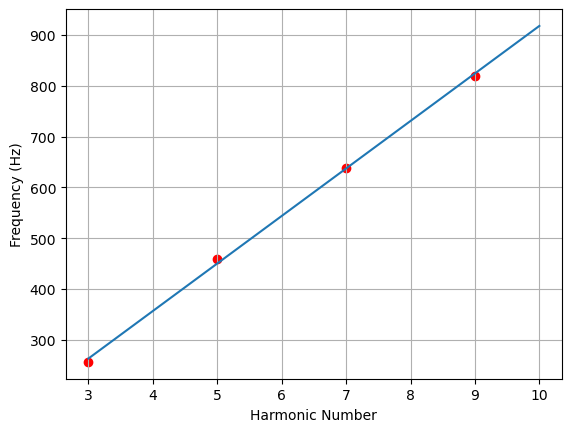

In [47]:
# Model With Constant

n_const = sm.add_constant(n)
model = sm.OLS(freq, n_const).fit()

x = np.linspace(3, 10, 1000)
x_const = sm.add_constant(x)
plt.scatter(n, freq, c='r')
plt.plot(x, model.predict(x_const))
plt.grid()
plt.xlabel('Harmonic Number')
plt.ylabel('Frequency (Hz)')

L = 0.918
end_correction = 0.6133 * 0.038
T = 26.592 # Celsius
print(f'm = {model.params[1]:.6f} +- {model.bse[1]:.6f}\nc = {model.params[0]:.6f} +- {model.bse[0]:.6f}')
print(f'v_ex = {model.params[1]*4*(0.918 + end_correction)} m/s')
print(f'v_th = {331.3 * np.sqrt(1 + (T/273.15))} m/s')


m = 90.968967 +- 0.788022
v_ex = 342.51832128723026 m/s
v_th = 347.13261641626247 m/s


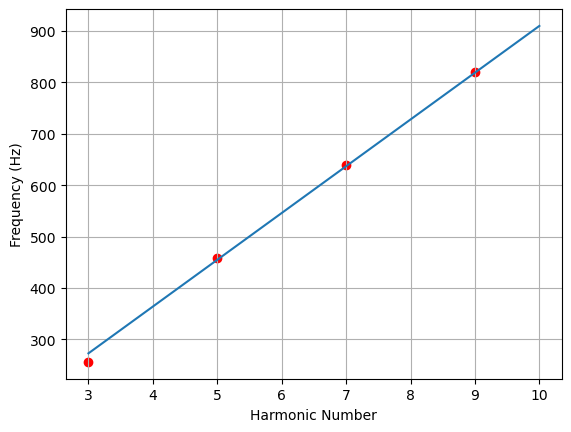

In [30]:
# Without Constant

n_const = sm.add_constant(n)
model = sm.OLS(freq, n).fit()

x = np.linspace(3, 10, 1000)
x_const = sm.add_constant(x)
plt.scatter(n, freq, c='r')
plt.plot(x, model.predict(x))
plt.grid()
plt.xlabel('Harmonic Number')
plt.ylabel('Frequency (Hz)')

L = 0.918
end_correction = 0.6133 * 0.038
T = 26.592 # Celsius
print(f'm = {model.params[0]:.6f} +- {model.bse[0]:.6f}')
print(f'v_ex = {model.params[0]*4*(0.918 + end_correction)} m/s')
print(f'v_th = {20.05 * np.sqrt(273.16 + T)} m/s')

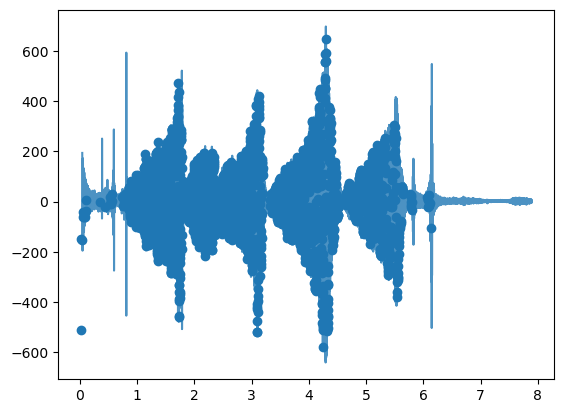

In [99]:
# Data obtained from raw IOlab data using FT

Dat1 = pd.read_csv('CapDat2.csv')
Dat2 = pd.read_csv('CapDat3.csv')

time1 = Dat1['Time (s)'].to_numpy()
intensity1 = Dat1['Intensity'].to_numpy()

time2 = Dat2['Time (s)'].to_numpy()
intensity2 = Dat2['Intensity'].to_numpy()

freq1 = np.fft.fft(intensity1)
freq2 = np.fft.fft(intensity2)

plt.plot(time1[100:-20000], np.real(freq1[100:-20000]), alpha=0.8)
peaks, _ = scipy.signal.find_peaks(np.real(freq1[100:-20000]), prominence=100)
plt.scatter(time1[peaks], np.real(freq1[peaks]))
#print(np.real(freq1[peaks]))


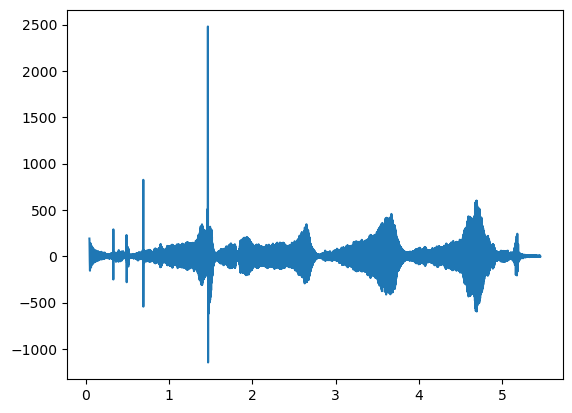

In [54]:
plt.plot(time2[100:-20000], np.real(freq2[100:-20000]))